In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/My Drive/Colab Notebooks/Feature Engineering/titanic.csv'


Mounted at /content/drive


In [ ]:
df = pd.read_csv(path)
df_raw = df.copy()

In [ ]:
print('Rows, Columns:', df.shape)

Rows, Columns: (891, 12)


In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# tail() shows the last 5 rows - useful to check the end of the file looks fine
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# dtypes shows only the data type
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
# isnull() marks empty cells as True; sum() counts them for each column
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
# What percentage of each column is missing?
(df.isnull().mean() * 100).round(1)

,0
PassengerId,0.0
Survived,0.0
Pclass,0.0
Name,0.0
Sex,0.0
Age,19.9
SibSp,0.0
Parch,0.0
Ticket,0.0
Fare,0.0


**Method 1 – `dropna()`

In [ ]:
# dropna() removes every row that has at least one missing value
df_dropna = df.dropna()

print('Rows before dropna:', df.shape[0])
print('Rows after  dropna:', df_dropna.shape[0])
# Only 183 of 891 rows are left, so dropping rows is a bad choice here

In [ ]:
#replace missing ages with the average age of all passengers
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [ ]:
# replace the 2 missing values with the most frequent port
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [ ]:
# most values are missing so we remove the whole column
df = df.drop(columns=['Cabin'])

In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
# astype('category') converts a column into the category type
df['Sex'] = df['Sex'].astype('category')
df['Embarked'] = df['Embarked'].astype('category')
df['Pclass'] = df['Pclass'].astype('category')

In [ ]:
# Confirm that the three columns are now of type "category"
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,category
Name,object
Sex,category
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
# Safety check
df.loc[(df['Sex'] != 'female') & (df['Sex'] != 'male')]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked


In [ ]:
df_enc = df.copy()

In [ ]:
# Label encoding: .cat.codes gives each category a number starting from 0
# Pclass 1 -> 0, 2 -> 1, 3 -> 2
df_enc['Pclass_code'] = df_enc['Pclass'].cat.codes

df_enc[['Pclass', 'Pclass_code']].head()

,Pclass,Pclass_code
0,3,2
1,1,0
2,3,2
3,1,0
4,3,2


In [ ]:
# Mapping- male = 1, female = 0
df_enc['Sex_male'] = df_enc['Sex'].map({'male': 1, 'female': 0}).astype(int)

df_enc[['Sex', 'Sex_male']].head()

,Sex,Sex_male
0,male,1
1,female,0
2,female,0
3,female,0
4,male,1


In [ ]:
# One-hot encoding
embarked_dummies = pd.get_dummies(df_enc['Embarked'], prefix='Embarked', drop_first=True, dtype=int)

# Add new columns to our table
df_enc = pd.concat([df_enc, embarked_dummies], axis=1)

df_enc[['Embarked', 'Embarked_Q', 'Embarked_S']].head()

,Embarked,Embarked_Q,Embarked_S
0,S,0,1
1,C,0,0
2,S,0,1
3,S,0,1
4,S,0,1


In [ ]:
# Comparing table size before and after encoding
print('Columns before encoding:', df.shape[1])
print('Columns after  encoding:', df_enc.shape[1])

Columns before encoding: 11
Columns after  encoding: 15


In [ ]:
# FamilySize = siblings/spouse + parents/children + the passenger himself/herself
df_enc['FamilySize'] = df_enc['SibSp'] + df_enc['Parch'] + 1

In [ ]:
# IsAlone = 1 if the passenger travelled alone (FamilySize is 1) otherwise 0
df_enc['IsAlone'] = np.where(df_enc['FamilySize'] == 1, 1, 0)

df_enc[['SibSp', 'Parch', 'FamilySize', 'IsAlone']].head()

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1


In [ ]:
alone_survival = df_enc.groupby('IsAlone')['Survived'].mean().round(3)
print(alone_survival)

IsAlone
0    0.506
1    0.304
Name: Survived, dtype: float64


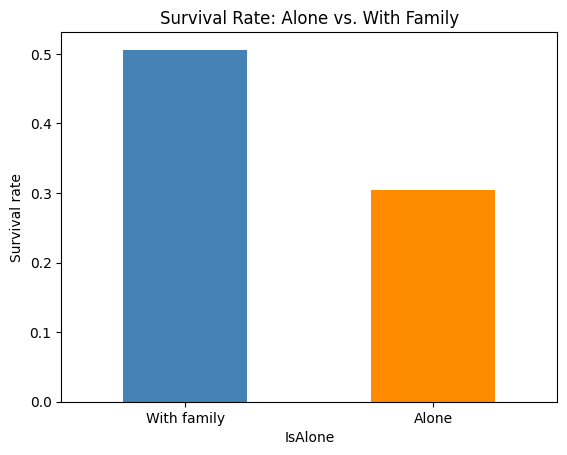

In [ ]:
# A bar chart of the above result
alone_survival.plot(kind='bar', color=['steelblue', 'darkorange'])
plt.xticks([0, 1], ['With family', 'Alone'], rotation=0)
plt.ylabel('Survival rate')
plt.title('Survival Rate: Alone vs. With Family')
plt.show()

In [ ]:
# Final table
print('Final shape:', df_enc.shape)
print('Missing values left:', int(df_enc.isnull().sum().sum()))
df_enc.head()

Final shape: (891, 17)
Missing values left: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Pclass_code,Sex_male,Embarked_Q,Embarked_S,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,2,1,0,1,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,0,0,0,0,2,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,2,0,0,1,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,0,0,0,1,2,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,2,1,0,1,1,1
